# Mall Customers (Kaggle)

Plote a inércia para k = 1..10 e encontre o 'cotovelo' na prática.

**Fonte:** https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python

> Notebook gerado em mslacerda.com — módulo *Avaliação de Clusters*. Execute as células em ordem (Shift+Enter).

## 1. Carregar os dados

In [ ]:
# Requires a free Kaggle account: kaggle.com/settings -> "Create New API Token",
# then upload kaggle.json when prompted.
!pip -q install kagglehub

import kagglehub, glob
import pandas as pd

path = kagglehub.dataset_download("vjchoudhary7/customer-segmentation-tutorial-in-python")
df = pd.read_csv(glob.glob(f"{path}/*.csv")[0])
print(df.shape)
df.head()

Using Colab cache for faster access to the 'customer-segmentation-tutorial-in-python' dataset.
(200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


## 2. Explore!

Sugestões de primeiros passos:

1. Inspecione `df.shape`, `df.dtypes` e `df.describe()` — o que cada coluna significa?
2. Há valores faltantes ou outliers? Como você os trataria?
3. Aplique uma técnica deste módulo (*Avaliação de Clusters*) e descreva o que encontrou.

In [ ]:
(df.shape)

(200, 5)

In [ ]:
(df.describe())

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [ ]:
(df.dtypes)

,0
CustomerID,int64
Gender,object
Age,int64
Annual Income (k$),int64
Spending Score (1-100),int64


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
print("Valores ausentes por coluna:")
display(df.isna().sum().to_frame("N ausentes"))
print(f"\nLinhas exatamente duplicadas: {df.duplicated().sum():,}")

Valores ausentes por coluna:


,N ausentes
CustomerID,0
Gender,0
Age,0
Annual Income (k$),0
Spending Score (1-100),0



Linhas exatamente duplicadas: 0


In [ ]:
colunas = ["Annual Income (k$)", "Spending Score (1-100)", "Age"]

for coluna in colunas:
    Q1 = df[coluna].quantile(0.25)
    Q3 = df[coluna].quantile(0.75)
    IQR = Q3 - Q1
    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    outliers = df[
        (df[coluna] < limite_inferior) |
        (df[coluna] > limite_superior)
    ]
    print(f'{coluna}: {len(outliers)} outliers')

Annual Income (k$): 2 outliers
Spending Score (1-100): 0 outliers
Age: 0 outliers


In [ ]:
Q1 = df['Annual Income (k$)'].quantile(0.25)
Q3 = df['Annual Income (k$)'].quantile(0.75)

IQR = Q3 - Q1

inferior = Q1 - 1.5 * IQR
superior = Q3 + 1.5 * IQR

df[
    (df['Annual Income (k$)'] < inferior) |
    (df['Annual Income (k$)'] > superior)
]

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
198,199,Male,32,137,18
199,200,Male,30,137,83


In [ ]:
df_2 = df.copy()

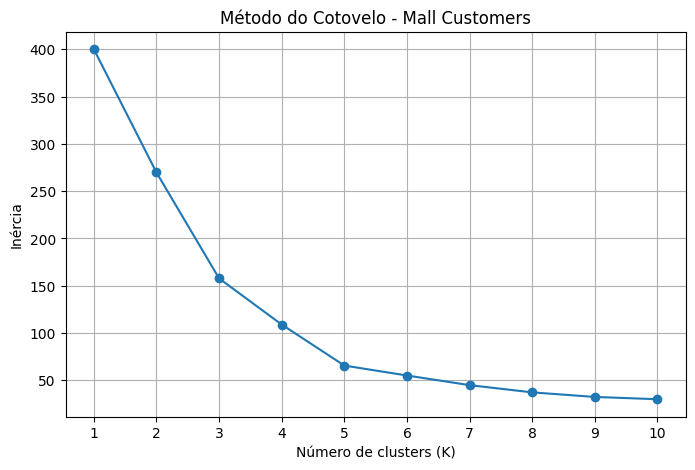

In [ ]:
from sklearn.cluster import KMeans
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

X = df[['Annual Income (k$)', 'Spending Score (1-100)']]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Testar quantidade de Clusters
inercias = []
for k in range(1, 11):
   km = KMeans(n_clusters=k, n_init=10, random_state=42)
   km.fit(X_scaled)
   inercias.append(km.inertia_)

   # Construir o gráfico do cotovelo
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), inercias, marker='o')

plt.title('Método do Cotovelo - Mall Customers')
plt.xlabel('Número de clusters (K)')
plt.ylabel('Inércia')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

In [ ]:
# Ajustar K-Means
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(X_scaled)

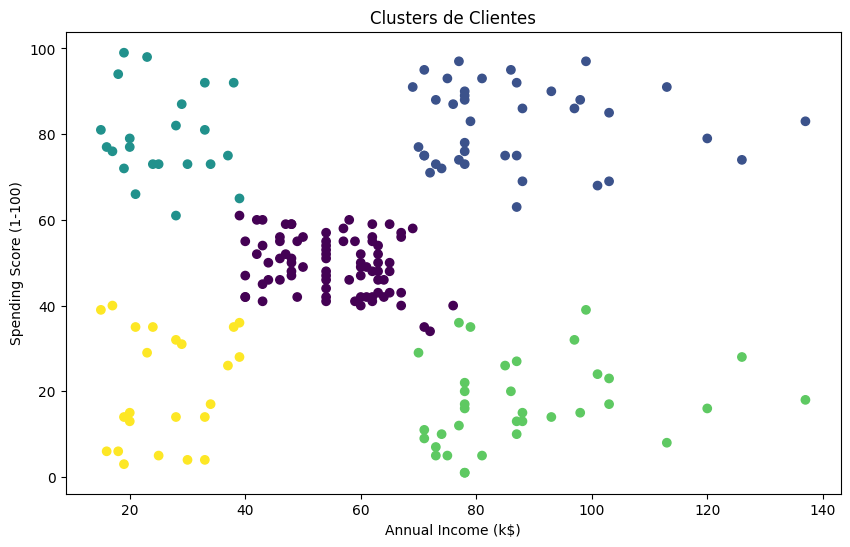

In [ ]:
plt.figure(figsize=(10, 6))
plt.scatter(df['Annual Income (k$)'], df['Spending Score (1-100)'], c=df['Cluster'], cmap='viridis')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title('Clusters de Clientes')
plt.show()

# 1. Silhouette Score — Índice de Silhueta

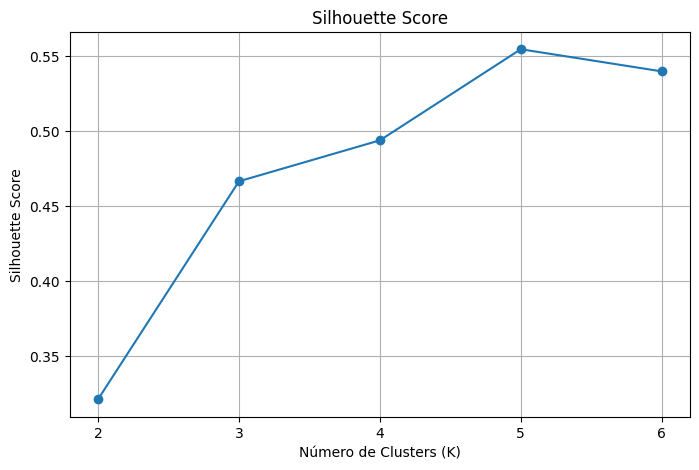

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

X_Silueta = df[['Annual Income (k$)', 'Spending Score (1-100)']].copy()
scaler = StandardScaler()
X_Silueta_scaled = scaler.fit_transform(X_Silueta)

silhuetas = []

for k in range(2, 7):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_Silueta_scaled)
    score = silhouette_score(X_Silueta_scaled, labels)
    silhuetas.append(score)

# Gráfico
plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 7),
    silhuetas,
    marker='o'
)
plt.title('Silhouette Score')
plt.xlabel('Número de Clusters (K)')
plt.ylabel('Silhouette Score')
plt.xticks(range(2, 7))
plt.grid(True)

plt.show()

In [ ]:
# Melhor k = maior silhouette score
km = KMeans(n_clusters=5, n_init=10, random_state=42)
labels = km.fit_predict(X_Silueta)
sample_scores = silhouette_samples(X_Silueta, labels)
print(f"\nMelhor (k=5): média={sample_scores.mean():.3f}")


Melhor (k=5): média=0.554


Para k = 3, a média do coeficiente de silhueta é: 0.468


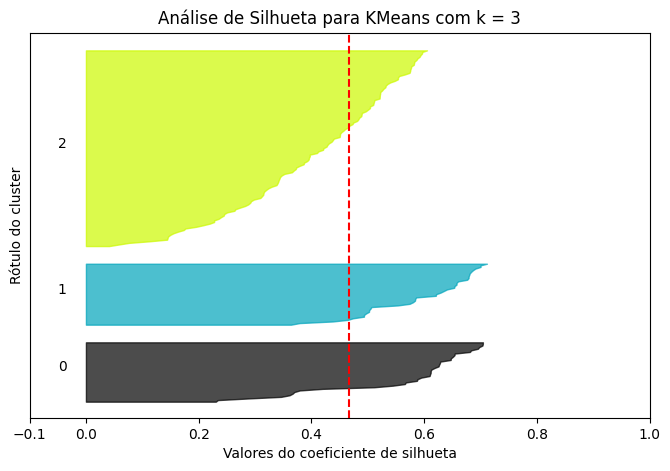

Para k = 4, a média do coeficiente de silhueta é: 0.494


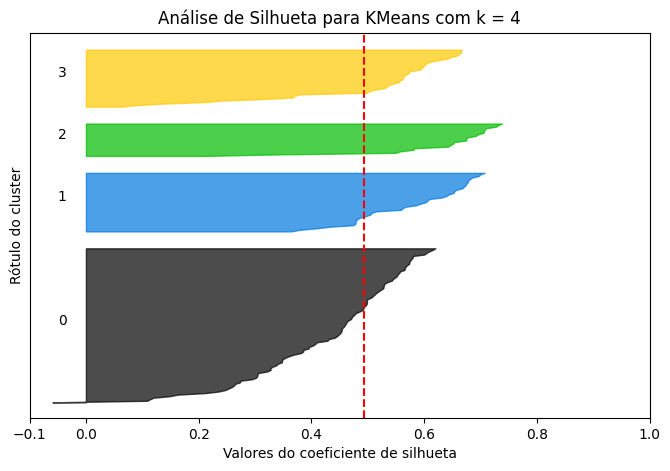

Para k = 5, a média do coeficiente de silhueta é: 0.554


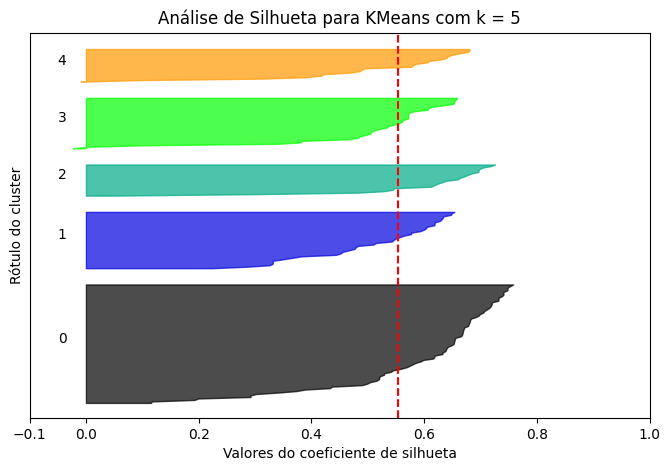

Para k = 6, a média do coeficiente de silhueta é: 0.513


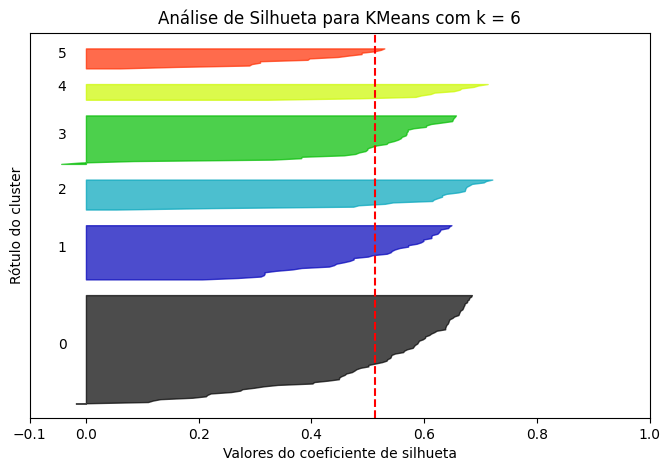

Para k = 7, a média do coeficiente de silhueta é: 0.502


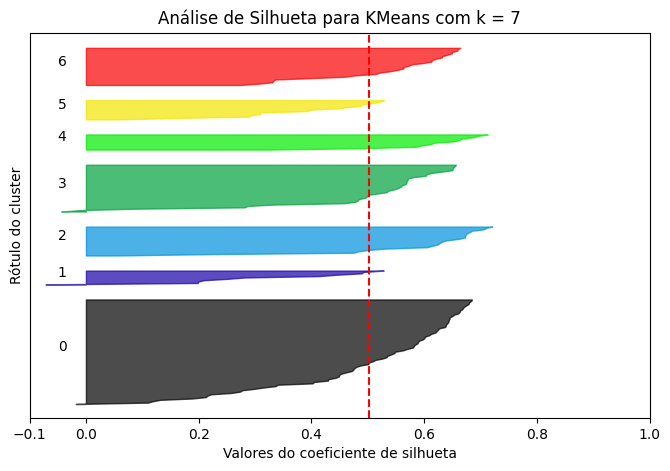

Para k = 8, a média do coeficiente de silhueta é: 0.496


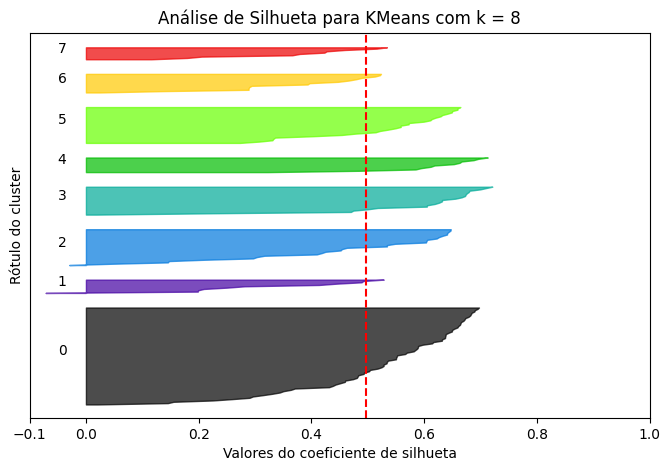

In [ ]:
import matplotlib.cm as cm

# Definir o intervalo de clusters (silhueta requer k >= 2)
ranges_k = [3, 4, 5, 6, 7, 8]

for n_clusters in ranges_k:
    # Criar uma figura com 1 linha e 1 coluna
    fig, ax1 = plt.subplots(1, 1)
    fig.set_size_inches(8, 5)

    # O gráfico de silhueta é delimitado por [-0.1, 1]
    ax1.set_xlim([-0.1, 1])
    # Inserir espaço em branco entre os gráficos para os clusters
    ax1.set_ylim([0, len(X_Silueta) + (n_clusters + 1) * 10])

    # Inicializar o clusterer com n_clusters
    clusterer = KMeans(n_clusters=n_clusters, random_state=42)
    cluster_labels = clusterer.fit_predict(X_Silueta)

    # Calcular a média do score de silhueta geral
    silhouette_avg = silhouette_score(X_Silueta, cluster_labels)
    print(f"Para k = {n_clusters}, a média do coeficiente de silhueta é: {silhouette_avg:.3f}")

    # Calcular o valor de silhueta para cada amostra
    sample_silhouette_values = silhouette_samples(X_Silueta, cluster_labels)

    y_lower = 10
    for i in range(n_clusters):
        # Agrupar os valores de silhueta das amostras do cluster i e ordená-los
        ith_cluster_silhouette_values = sample_silhouette_values[cluster_labels == i]
        ith_cluster_silhouette_values.sort()

        size_cluster_i = ith_cluster_silhouette_values.shape[0]
        y_upper = y_lower + size_cluster_i

        color = cm.nipy_spectral(float(i) / n_clusters)
        ax1.fill_betweenx(
            np.arange(y_lower, y_upper),
            0,
            ith_cluster_silhouette_values,
            facecolor=color,
            edgecolor=color,
            alpha=0.7,
        )

        # Rotular os gráficos de silhueta com seus números de cluster no meio
        ax1.text(-0.05, y_lower + 0.5 * size_cluster_i, str(i))

        # Computar o novo y_lower para o próximo gráfico
        y_lower = y_upper + 10  # 10 para as linhas em branco

    ax1.set_title(f"Análise de Silhueta para KMeans com k = {n_clusters}")
    ax1.set_xlabel("Valores do coeficiente de silhueta")
    ax1.set_ylabel("Rótulo do cluster")

    # A linha vertical tracejada para a média do score de silhueta de todos os valores
    ax1.axvline(x=silhouette_avg, color="red", linestyle="--")

    ax1.set_yticks([])  # Limpar os yticks / rótulos
    ax1.set_xticks([-0.1, 0, 0.2, 0.4, 0.6, 0.8, 1])

    plt.show()

# 2. Índice Dunn

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import pairwise_distances

X_Dunn = df[['Annual Income (k$)', 'Spending Score (1-100)']].copy()
dunn = []

for z in range(2,10):
  km = KMeans(n_clusters=z, n_init=10, random_state=42)
  labels = km.fit_predict(X_Dunn)

  def dunn_index(X, labels):
      clusters = set(labels)
      inter_dists = []
      intra_diams = []
      for ci in clusters:
          pts_i = X_Dunn[labels == ci]
          intra_diams.append(pairwise_distances(pts_i).max())
          for cj in clusters:
              if ci < cj:
                  pts_j = X_Dunn[labels == cj]
                  inter_dists.append(
                      pairwise_distances(pts_i, pts_j).min()
                  )

      return min(inter_dists) / max(intra_diams)
for z in range(2, 10):
    km = KMeans(n_clusters=z, n_init=10, random_state=42)
    labels = km.fit_predict(X_Dunn)

    score = dunn_index(X_Dunn.values, labels)
    dunn.append(score)  # ✅ append fora da função, dentro do loop
    print(f"Para N° Cluster = {z} | Índice Dunn: {score:.4f}")

  #print(f"Para N° Cluester = {z} | Índice Dunn: {dunn_index(X_Dunn, labels):.4f}")

Para N° Cluster = 2 | Índice Dunn: 0.0197
Para N° Cluster = 3 | Índice Dunn: 0.0667
Para N° Cluster = 4 | Índice Dunn: 0.0800
Para N° Cluster = 5 | Índice Dunn: 0.0584
Para N° Cluster = 6 | Índice Dunn: 0.0589
Para N° Cluster = 7 | Índice Dunn: 0.0921
Para N° Cluster = 8 | Índice Dunn: 0.0449
Para N° Cluster = 9 | Índice Dunn: 0.0502


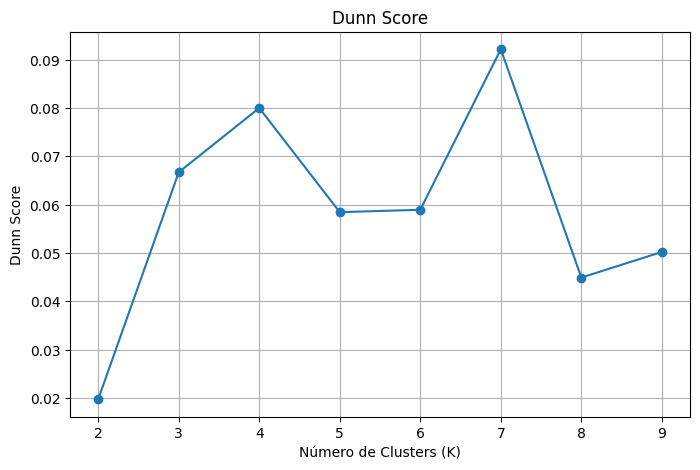

In [ ]:
# Gráfico
plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 10),
    dunn,
    marker='o'
)
plt.title('Dunn Score')
plt.xlabel('Número de Clusters (K)')
plt.ylabel('Dunn Score')
plt.xticks(range(2, 10))
plt.grid(True)

plt.show()

#3. Índice Davies-Bouldin

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import davies_bouldin_score
import numpy as np

X_davis = df[['Annual Income (k$)', 'Spending Score (1-100)']].copy()
davis = []

for k in range(2, 10):
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X_davis)
    db = davies_bouldin_score(X_davis, labels)
    davis.append(db)
    print(f"k={k}: Davies-Bouldin = {db:.3f}")

print("\nMelhor k → menor Davies-Bouldin score")

k=2: Davies-Bouldin = 1.257
k=3: Davies-Bouldin = 0.715
k=4: Davies-Bouldin = 0.710
k=5: Davies-Bouldin = 0.573
k=6: Davies-Bouldin = 0.652
k=7: Davies-Bouldin = 0.711
k=8: Davies-Bouldin = 0.759
k=9: Davies-Bouldin = 0.763

Melhor k → menor Davies-Bouldin score


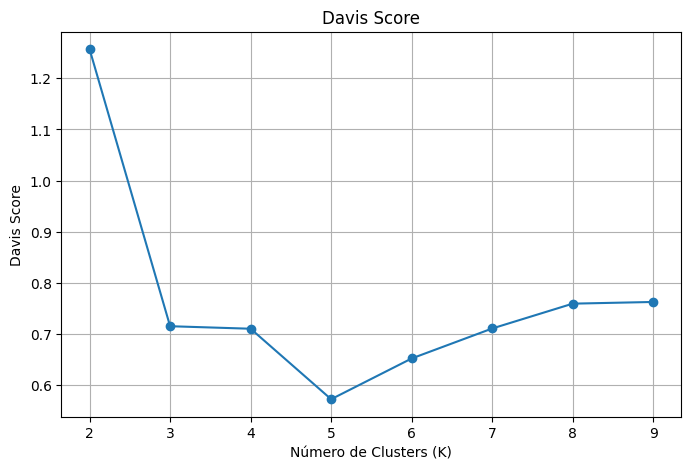

In [ ]:
# Gráfico
plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 10),
    davis,
    marker='o'
)
plt.title('Davis Score')
plt.xlabel('Número de Clusters (K)')
plt.ylabel('Davis Score')
plt.xticks(range(2, 10))
plt.grid(True)

plt.show()